In [1]:
!pip install -q -U transformers accelerate

import os
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"
import re
import json
import glob
import time
import subprocess
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from PIL import Image
from transformers import AutoProcessor, Qwen2_5_VLForConditionalGeneration

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.26.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
device: cuda


In [2]:
MODEL_NAME = "Qwen/Qwen2.5-VL-7B-Instruct"

processor = AutoProcessor.from_pretrained(
    MODEL_NAME,
    min_pixels=256 * 28 * 28,
    max_pixels=1024 * 28 * 28,
)
model = Qwen2_5_VLForConditionalGeneration.from_pretrained(
    MODEL_NAME,
    torch_dtype=torch.float16,
    device_map="auto",
    max_memory={0: "12GiB", 1: "12GiB"},
    attn_implementation="sdpa",
)
DT = torch.float16
model.eval()
for p_ in model.parameters():
    p_.requires_grad_(False)

lm = model.model.language_model
lm_head = model.lm_head
layers = lm.layers
n_layer = model.config.text_config.num_hidden_layers
n_head = model.config.text_config.num_attention_heads
hidden_dim = model.config.text_config.hidden_size
head_dim = layers[0].self_attn.o_proj.in_features // n_head
IMAGE_TOKEN_ID = model.config.image_token_id
assert len(layers) == n_layer
print(n_layer, "language model layers,", n_head, "heads,", head_dim, "head dim, image token id", IMAGE_TOKEN_ID, "| attention", model.config.text_config._attn_implementation)

preprocessor_config.json:   0%|          | 0.00/350 [00:00<?, ?B/s]

chat_template.json:   0%|          | 0.00/1.05k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.37k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/5.70k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

...

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 5 files:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/729 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/216 [00:00<?, ?B/s]

28 language model layers, 28 heads, 128 head dim, image token id 151655 | attention sdpa


In [3]:
INPUT = "/kaggle/input/datasets/nocturnalnerd18"
USERNAME = "nocturnalnerd18"
AMBER_IMAGE_DIR = "/kaggle/input/datasets/nocturnalnerd18/amber-hallucination/image"

N_UNITS = 93
DRIVEN_TE = -1.0
SLUG = f"{USERNAME}/patch-qwen-circuit-dissect"
MAX_HOURS = 9.0
PILOT_UNITS = 2
BATCH_SAVE_SIZE = 20
UPLOAD_EVERY = 2
CHECK_TOL = 0.25
TAIL_N = 5
GROUPS = ["visual", "text", "tail"]
OUT_DIR = "/kaggle/working/patch_qwen_circuit_dissect"
os.makedirs(OUT_DIR, exist_ok=True)

SHARED = [("head", 15, 26, "all"), ("mlp", 17, -1, "all"), ("mlp", 18, -1, "all"), ("mlp", 19, -1, "all"), ("mlp", 20, -1, "all"), ("mlp", 21, -1, "all")]
SPECIFIC = [("mlp", 1, -1, "visual"), ("mlp", 14, -1, "all"), ("mlp", 15, -1, "all"), ("head", 20, 2, "all")]


def load_image(path):
    return Image.open(path).convert("RGB")


def build_inputs(image, text):
    conversation = [{"role": "user", "content": [{"type": "image"}, {"type": "text", "text": text}]}]
    prompt_text = processor.apply_chat_template(conversation, add_generation_prompt=True)
    return processor(text=prompt_text, images=image, return_tensors="pt").to(model.device, DT)


def resolve_image_path(q):
    if q["question_id"].startswith("amber_"):
        return os.path.join(AMBER_IMAGE_DIR, f"{q['image_id']}.jpg")
    return None


def batch_number(path):
    return int(re.search(r"_batch_(\d+)\.pt$", path).group(1))


with open(f"{INPUT}/vlm-questions/all_questions.json") as f:
    all_questions = json.load(f)
assert len(all_questions) == 17492, "attach vlm-questions version 2"
question_by_id = {q["question_id"]: q for q in all_questions}
with open(f"{INPUT}/dla-qwen/dla_meta.json") as f:
    dla_meta = json.load(f)
PAIRS = {k: tuple(v) for k, v in dla_meta["pairs"].items()}
for prefix, (yes_id, no_id) in PAIRS.items():
    words = [processor.tokenizer.decode([i]).strip() for i in (yes_id, no_id)]
    print(prefix, yes_id, no_id, words)
    assert [w.lower() for w in words] == ["yes", "no"], words
assert "amber_" in PAIRS

atp = {}
atp_files = sorted(glob.glob(f"{INPUT}/atp-qwen-noising/**/*_batch_*.pt", recursive=True), key=lambda p: (os.path.basename(p).split("_batch_")[0], batch_number(p)))
for path in atp_files:
    for e in torch.load(path):
        if e["ok"]:
            atp[e["question_id"]] = {k: e[k] for k in (
                "question_id", "image_id", "hallucination_type", "stratum", "group", "source", "split", "sign", "seed",
                "delta_clean", "delta_corrupt", "TE", "noise_used",
            )}
print(f"atp-qwen-noising: {len(atp_files)} batch files, {len(atp)} ok entries")
assert len(atp) >= 0.98 * 2927, "attach atp-qwen-noising (all batches)"

meta = pd.DataFrame([{k: v for k, v in a.items() if k not in ("head", "mlp")} for a in atp.values()])
meta["gap_clean"] = meta.sign * meta.delta_clean


def image_ok(qid):
    path = resolve_image_path(question_by_id[qid])
    return path is not None and os.path.exists(path)

fy_all = meta[(meta.stratum == "false_yes") & (meta.hallucination_type == "attribute") & (meta.TE < DRIVEN_TE)]
ty_all = meta[(meta.stratum == "true_yes") & (meta.hallucination_type == "attribute")]
rng = np.random.default_rng(0)
units = []
for (s, sp), g in fy_all.groupby(["source", "split"]):
    pool = ty_all[(ty_all.source == s) & (ty_all.split == sp)].set_index("question_id").gap_clean
    ids = g.question_id.tolist()
    gaps = g.set_index("question_id").gap_clean
    for rank, i in enumerate(rng.permutation(len(ids))):
        qid = ids[i]
        ctrl = None
        if len(pool):
            ctrl = (pool - gaps[qid]).abs().idxmin()
            pool = pool.drop(ctrl)
        units.append({"fy": qid, "ctrl": ctrl, "key": (rank + 0.5) / len(ids), "stratum": f"{s}/{sp}"})
units.sort(key=lambda u: (u["key"], u["stratum"]))
units = [u for u in units if image_ok(u["fy"]) and (u["ctrl"] is None or image_ok(u["ctrl"]))]
for i, u in enumerate(units):
    u["uid"] = i
print(len(units), "driven attribute false_yes units,", sum(u["ctrl"] is not None for u in units), "with a matched true_yes control")
stage_units = units[:N_UNITS]
uid_of = {}
for u in stage_units:
    uid_of[u["fy"]] = u["uid"]
    if u["ctrl"] is not None:
        uid_of[u["ctrl"]] = u["uid"]
stage_ids = list(uid_of)
print(f"{len(stage_units)} units, {len(stage_ids)} questions")
print(pd.Series([u["stratum"] for u in stage_units]).value_counts().to_string())


def cell_name(entries):
    kind, layer, head = entries[0][0], entries[0][1], entries[0][2]
    groups = {e[3] for e in entries}
    base = f"L{layer} H{head}" if kind == "head" else f"L{layer} MLP"
    return base if len(groups) > 1 or "all" in groups else f"{base}[{next(iter(groups))}]"


members = {}
for c in SHARED + SPECIFIC:
    members.setdefault(c[:3], []).append(c)
S_KEYS = [k_ for k_ in members if any(e in SHARED for e in members[k_])]
K_KEYS = [k_ for k_ in members if k_ not in S_KEYS]
SK_KEYS = S_KEYS + K_KEYS
NAME = {k_: cell_name(members[k_]) for k_ in members}
ROLE = {k_: "shared" if k_ in S_KEYS else "specific" for k_ in members}
print("shared cells:", [NAME[k_] for k_ in S_KEYS])
print("specific cells:", [NAME[k_] for k_ in K_KEYS])


def comps_of(keys, skip=None):
    return [e for k_ in keys if k_ != skip for e in members[k_]]


STEP_COMPS = {"S": comps_of(S_KEYS), "K": comps_of(K_KEYS), "SK": comps_of(SK_KEYS)}
for k_ in SK_KEYS:
    STEP_COMPS[f"single:{NAME[k_]}"] = list(members[k_])
for k_ in SK_KEYS:
    STEP_COMPS[f"loo_SK:{NAME[k_]}"] = comps_of(SK_KEYS, skip=k_)
STEP_NAMES = list(STEP_COMPS)
print(len(STEP_NAMES), "steps,", 2 * len(STEP_NAMES), "forwards per question")


def prep(qid):
    q = question_by_id[qid]
    inputs = build_inputs(load_image(resolve_image_path(q)), q["question_text"])
    ids = inputs["input_ids"]
    T = ids.shape[1]
    vis = ids[0] == IMAGE_TOKEN_ID
    tail = torch.zeros(T, dtype=torch.bool, device=ids.device)
    tail[-TAIL_N:] = True
    text = ~vis & ~tail
    assert int(vis.sum()) == int(inputs["image_grid_thw"].prod()) // 4 and not bool((vis & tail).any())
    yes_id, no_id = PAIRS[qid.split("_")[0] + "_"]
    return {
        "qid": qid, "T": T, "inputs": inputs, "vis": vis, "yes_id": yes_id, "no_id": no_id,
        "idx": {
            "all": torch.arange(T), "visual": torch.nonzero(vis.cpu())[:, 0],
            "text": torch.nonzero(text.cpu())[:, 0], "tail": torch.nonzero(tail.cpu())[:, 0],
        },
        "sign": 1.0 if q["ground_truth_answer"].strip().lower() == "yes" else -1.0,
    }

amber_ 9454 2753 ['Yes', 'No']
reefknot_ 9693 2152 ['yes', 'no']
atp-qwen-noising: 15 batch files, 2927 ok entries
93 driven attribute false_yes units, 93 with a matched true_yes control
93 units, 186 questions
amber/train    73
amber/test     10
amber/val      10
shared cells: ['L15 H26', 'L17 MLP', 'L18 MLP', 'L19 MLP', 'L20 MLP', 'L21 MLP']
specific cells: ['L1 MLP[visual]', 'L14 MLP', 'L15 MLP', 'L20 H2']
23 steps, 46 forwards per question


In [4]:
STATE = {"noise": None, "seed": 0, "capture": False, "live": None, "vis": None, "freeze": None}


def _layer_pre(l):
    def hook(module, args, kwargs):
        if l != 0 or STATE["noise"] is None:
            return None
        h = args[0] if args else kwargs["hidden_states"]
        vis = STATE["vis"]
        h = h.clone()
        x = h[:, vis].float()
        generator = torch.Generator().manual_seed(STATE["seed"])
        noise = torch.randn(x.shape, generator=generator).to(h.device)
        h[:, vis] = (x + noise * x.std() * STATE["noise"]).to(h.dtype)
        if args:
            return (h,) + tuple(args[1:]), kwargs
        kwargs = dict(kwargs)
        kwargs["hidden_states"] = h
        return args, kwargs
    return hook


def _z_pre(l):
    def hook(module, args):
        z = args[0]
        fz = STATE["freeze"]
        if fz is not None:
            m = fz["z"][l]
            if m is None:
                return None
            B, T = z.shape[0], z.shape[1]
            src = fz["src"]["z"][l][0].view(T, n_head, head_dim).to(z.device, z.dtype)
            z4 = torch.where(m.to(z.device)[None, :, :, None], src[None], z.view(B, T, n_head, head_dim))
            return (z4.view(B, T, n_head * head_dim),) + tuple(args[1:])
        if STATE["capture"]:
            STATE["live"]["z"][l] = z
        return None
    return hook


def _mlp_fwd(l):
    def hook(module, args, output):
        fz = STATE["freeze"]
        if fz is not None:
            m = fz["m"][l]
            if m is None:
                return None
            src = fz["src"]["mlp"][l][0].to(output.device, output.dtype)
            return torch.where(m.to(output.device)[None, :, None], src[None], output)
        if STATE["capture"]:
            STATE["live"]["mlp"][l] = output
        return None
    return hook


_handles = []
for l, layer in enumerate(layers):
    _handles.append(layer.register_forward_pre_hook(_layer_pre(l), with_kwargs=True))
    _handles.append(layer.self_attn.o_proj.register_forward_pre_hook(_z_pre(l)))
    _handles.append(layer.mlp.register_forward_hook(_mlp_fwd(l)))
print(len(_handles), "hooks registered")

84 hooks registered


In [5]:
@torch.no_grad()
def run_forward(p, noise, seed, freeze=None, capture=False):
    STATE.update(noise=noise, seed=seed, capture=capture, freeze=freeze, vis=p["vis"])
    if capture:
        STATE["live"] = {"z": [None] * n_layer, "mlp": [None] * n_layer}
    out = model(**p["inputs"], use_cache=False, logits_to_keep=1)
    logits = out.logits[0, -1].float()
    delta = float(p["sign"] * (logits[p["yes_id"]] - logits[p["no_id"]]))
    result = {"acts": STATE["live"], "delta": delta} if capture else delta
    STATE.update(noise=None, capture=False, freeze=None, live=None)
    del out, logits
    return result


def build_mask(p, comps):
    T = p["T"]
    hm = torch.zeros(n_layer, T, n_head, dtype=torch.bool)
    mm = torch.zeros(n_layer, T, dtype=torch.bool)
    for kind, layer, head, group in comps:
        idx = p["idx"][group]
        if kind == "head":
            hm[layer, idx, head] = True
        else:
            mm[layer, idx] = True
    return hm, mm


def make_freeze(hm, mm, src, invert):
    zs, ms = [], []
    for l in range(n_layer):
        a, b = hm[l], mm[l]
        if invert:
            a, b = ~a, ~b
        zs.append(a if bool(a.any()) else None)
        ms.append(b if bool(b.any()) else None)
    return {"z": zs, "m": ms, "src": src["acts"]}


def two_configs(p, clean, corrupt, comps, seed, noise):
    hm, mm = build_mask(p, comps)
    knock = run_forward(p, None, seed, make_freeze(hm, mm, corrupt, False))
    restore = run_forward(p, noise, seed, make_freeze(hm, mm, clean, False))
    return [knock, restore]


CONFIG_NAMES = ["knockout", "restored"]


def circuit_curve(p, clean, corrupt, seed, noise):
    return np.array([two_configs(p, clean, corrupt, STEP_COMPS[n], seed, noise) for n in STEP_NAMES], dtype=np.float32)


ALL_COMPS = [("head", l, h, "all") for l in range(n_layer) for h in range(n_head)] + [("mlp", l, -1, "all") for l in range(n_layer)]

In [6]:
pilot_ids = [q for u in stage_units for q in (u["fy"], u["ctrl"]) if q is not None and image_ok(q)][:2 * PILOT_UNITS]
secs, base_err, id_err, plain_err = [], [], [], []
for qid in pilot_ids:
    a = atp[qid]
    p = prep(qid)
    t0 = time.time()
    clean = run_forward(p, None, a["seed"], capture=True)
    corrupt = run_forward(p, a["noise_used"], a["seed"], capture=True)
    base_err.append(max(abs(clean["delta"] - a["delta_clean"]), abs(corrupt["delta"] - a["delta_corrupt"])))
    plain_err.append(max(abs(run_forward(p, None, a["seed"]) - clean["delta"]), abs(run_forward(p, a["noise_used"], a["seed"]) - corrupt["delta"])))
    t_cap = time.time() - t0
    all_knock, all_restore = two_configs(p, clean, corrupt, ALL_COMPS, a["seed"], a["noise_used"])
    none_knock, none_restore = two_configs(p, clean, corrupt, [], a["seed"], a["noise_used"])
    id_err.append(max(abs(all_knock - corrupt["delta"]), abs(all_restore - clean["delta"]), abs(none_knock - clean["delta"]), abs(none_restore - corrupt["delta"])))
    t1 = time.time()
    curve = circuit_curve(p, clean, corrupt, a["seed"], a["noise_used"])
    secs.append(t_cap + time.time() - t1)
    print(f"{qid} {a['stratum']:9s} T={p['T']}: {secs[-1]:.1f} s for {len(STEP_NAMES)} steps | clean {clean['delta']:+.2f} (atp run {a['delta_clean']:+.2f}) corrupt {corrupt['delta']:+.2f} ({a['delta_corrupt']:+.2f})")
    print(pd.DataFrame(curve, index=STEP_NAMES, columns=CONFIG_NAMES).round(2).head(12).to_string())
    del p, clean, corrupt
    torch.cuda.empty_cache()
print(f"clean and corrupt deltas vs the attribution patching run: max abs diff {max(base_err):.3f}")
print(f"capture runs vs plain runs: max abs diff {max(plain_err):.3f}")
print(f"identity checks (freezing every component, or none, must give the other run or the same run): max abs error {max(id_err):.3f}")
print(f"pilot speed: {np.mean(secs):.1f} s per question, projected {np.mean(secs) * len(stage_ids) / 3600:.1f} h for {len(stage_ids)} questions")
assert max(base_err) < CHECK_TOL, "clean or corrupt deltas differ from the attribution patching collection"
assert max(plain_err) < CHECK_TOL, "capture runs differ from plain runs"
assert max(id_err) < CHECK_TOL, "freezing every component does not reproduce the other run"

/usr/local/lib/python3.13/dist-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(


amber_6622 false_yes T=374: 23.7 s for 23 steps | clean -4.06 (atp run -4.06) corrupt -2.66 (-2.66)
                       knockout  restored
S                         -2.84     -3.67
K                         -2.70     -2.14
SK                        -1.81     -3.77
single:L15 H26            -3.88     -3.34
single:L17 MLP            -4.31     -2.47
single:L18 MLP            -3.80     -2.61
single:L19 MLP            -3.55     -3.12
single:L20 MLP            -4.05     -2.72
single:L21 MLP            -3.70     -3.02
single:L1 MLP[visual]     -3.92     -3.84
single:L14 MLP            -1.89     -3.52
single:L15 MLP            -5.30     -2.27


/usr/local/lib/python3.13/dist-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(


amber_1225 true_yes  T=309: 21.9 s for 23 steps | clean +4.06 (atp run +4.06) corrupt +1.92 (+1.92)
                       knockout  restored
S                          1.59      4.69
K                          6.62     -0.56
SK                         2.47      3.94
single:L15 H26             4.16      1.98
single:L17 MLP             2.56      3.16
single:L18 MLP             2.97      2.42
single:L19 MLP             3.25      2.42
single:L20 MLP             3.42      2.58
single:L21 MLP             3.67      2.23
single:L1 MLP[visual]      6.36      2.34
single:L14 MLP             4.77     -0.03
single:L15 MLP             3.83      0.64


/usr/local/lib/python3.13/dist-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(


amber_5612 false_yes T=375: 23.4 s for 23 steps | clean -7.92 (atp run -7.92) corrupt -3.67 (-3.67)
                       knockout  restored
S                         -3.84     -8.16
K                         -7.75     -4.64
SK                        -3.88     -8.19
single:L15 H26            -7.28     -4.70
single:L17 MLP            -6.91     -5.66
single:L18 MLP            -6.39     -5.05
single:L19 MLP            -6.30     -5.16
single:L20 MLP            -7.06     -4.16
single:L21 MLP            -7.38     -4.11
single:L1 MLP[visual]    -10.14     -2.11
single:L14 MLP            -6.70     -6.92
single:L15 MLP            -7.52     -4.73


/usr/local/lib/python3.13/dist-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(


amber_6663 true_yes  T=328: 22.4 s for 23 steps | clean +7.88 (atp run +7.88) corrupt +0.19 (+0.19)
                       knockout  restored
S                          0.58      7.81
K                          6.91      0.05
SK                         0.25      8.30
single:L15 H26             7.33      0.05
single:L17 MLP             7.72      1.66
single:L18 MLP             3.64      3.47
single:L19 MLP             4.47      2.77
single:L20 MLP             4.05      2.39
single:L21 MLP             5.09      1.52
single:L1 MLP[visual]      7.91      0.39
single:L14 MLP             7.58      2.48
single:L15 MLP             7.86      0.31
clean and corrupt deltas vs the attribution patching run: max abs diff 0.000
capture runs vs plain runs: max abs diff 0.000
identity checks (freezing every component, or none, must give the other run or the same run): max abs error 0.000
pilot speed: 22.9 s per question, projected 1.2 h for 186 questions


In [7]:
def _run(cmd):
    r = subprocess.run(cmd, capture_output=True, text=True)
    out = (r.stdout + r.stderr).strip()
    cleaned = "\n".join(l for l in out.splitlines() if "upload info" not in l.lower()).lower()
    bad = ("client error", "forbidden", "unauthorized", "traceback", "error:", "failed")
    return r.returncode == 0 and not any(x in cleaned for x in bad), out


ok, out = _run(["kaggle", "datasets", "download", "-d", SLUG, "-p", OUT_DIR, "--unzip"])
if ok:
    print("restored", len(glob.glob(os.path.join(OUT_DIR, "C_batch_*.pt"))), "batch files from", SLUG)
else:
    if not any(s in out.lower() for s in ("404", "403", "not found", "does not exist", "forbidden")):
        raise RuntimeError("download failed for an unrelated reason, refusing to start fresh:\n" + out)
    print("no existing dataset, starting fresh")
dataset_exists = ok

with open(os.path.join(OUT_DIR, "dataset-metadata.json"), "w") as f:
    json.dump({
        "title": SLUG.split("/")[1],
        "id": SLUG,
        "subtitle": "Per-cell dissection of Qwen shared and specific sets",
        "description": "Per-cell dissection on Qwen2.5-VL-7B-Instruct of the shared evidence set and the hallucination-specific set for driven attribute false_yes questions (TE below -1) and matched true_yes controls from atp-qwen-noising. "
                       "curve has shape [step, 2] holding the sign-corrected Yes minus No logit gap at the last position for knockout (clean input, the set takes its corrupt activations) and restored (corrupt input, the set takes its clean activations). "
                       "Steps are the shared set S, the specific set K, both together SK, every cell alone (single) and each cell left out of SK (loo). Names are in circuit_meta.json.",
        "licenses": [{"name": "CC0-1.0"}],
    }, f)


def upload(msg):
    global dataset_exists
    version_cmd = ["kaggle", "datasets", "version", "-p", OUT_DIR, "-m", msg]
    create_cmd = ["kaggle", "datasets", "create", "-p", OUT_DIR]
    ok_, out_ = _run(version_cmd if dataset_exists else create_cmd)
    if not ok_ and not dataset_exists:
        time.sleep(30)
        ok_, out2 = _run(version_cmd)
        out_ += "\n--- version retry ---\n" + out2
    if ok_:
        dataset_exists = True
        print(f"    [upload ok] {msg}")
    else:
        cleaned = [l for l in out_.splitlines() if l.strip() and "upload info" not in l.lower() and "B/s]" not in l and "it/s]" not in l]
        print(f"    [UPLOAD FAILED, continuing] account {USERNAME}, dataset {SLUG}\n" + "\n".join(cleaned[-8:]))
    return ok_


with open(os.path.join(OUT_DIR, "circuit_meta.json"), "w") as f:
    json.dump({
        "step_names": STEP_NAMES, "config_names": CONFIG_NAMES, "steps": {n: [list(c) for c in STEP_COMPS[n]] for n in STEP_NAMES},
        "cells": {NAME[k_]: {"role": ROLE[k_], "members": [list(c) for c in members[k_]]} for k_ in members},
        "s_cells": [NAME[k_] for k_ in S_KEYS], "k_cells": [NAME[k_] for k_ in K_KEYS],
        "n_units": N_UNITS, "tail_n": TAIL_N, "pairs": {k_: list(v_) for k_, v_ in PAIRS.items()},
    }, f)


def collect():
    paths = sorted(glob.glob(os.path.join(OUT_DIR, "C_batch_*.pt")), key=batch_number)
    done_ids = set()
    for path in paths:
        done_ids.update(e["question_id"] for e in torch.load(path))
    todo = [q for q in stage_ids if q not in done_ids]
    print(f"{len(stage_ids)} questions, {len(done_ids)} already done, {len(todo)} to run")
    batch_entries, batch_index, failed, missing = [], len(paths), 0, 0
    t_start = time.time()
    stopped = False
    for i, qid in enumerate(todo):
        if not image_ok(qid):
            missing += 1
            continue
        a = atp[qid]
        q = question_by_id[qid]
        entry = {
            "question_id": qid, "uid": uid_of[qid], "image_id": q["image_id"], "stratum": a["stratum"], "source": a["source"], "split": a["split"],
            "sign": 1.0 if q["ground_truth_answer"].strip().lower() == "yes" else -1.0, "atp_delta_clean": a["delta_clean"], "atp_delta_corrupt": a["delta_corrupt"],
        }
        try:
            p = prep(qid)
            clean = run_forward(p, None, a["seed"], capture=True)
            corrupt = run_forward(p, a["noise_used"], a["seed"], capture=True)
            curve = circuit_curve(p, clean, corrupt, a["seed"], a["noise_used"])
            entry.update(ok=True, T=p["T"], delta_clean=clean["delta"], delta_corrupt=corrupt["delta"], curve=torch.from_numpy(curve))
            del p, clean, corrupt
        except torch.cuda.OutOfMemoryError:
            STATE.update(capture=False, live=None, noise=None, freeze=None)
            torch.cuda.empty_cache()
            entry.update(ok=False, reason="oom")
            failed += 1
        batch_entries.append(entry)
        if len(batch_entries) >= BATCH_SAVE_SIZE:
            torch.save(batch_entries, os.path.join(OUT_DIR, f"C_batch_{batch_index}.pt"))
            batch_entries, batch_index = [], batch_index + 1
            if batch_index % UPLOAD_EVERY == 0:
                upload(f"{batch_index} batches")
        if i % 10 == 0 and i > 0:
            torch.cuda.empty_cache()
            avg = (time.time() - t_start) / (i + 1)
            print(f"[{i + 1}/{len(todo)}] {qid} ({avg:.1f} s/question avg, ETA {avg * (len(todo) - i - 1) / 3600:.1f} h, failed {failed}, missing images {missing})")
        if time.time() - t_start > MAX_HOURS * 3600:
            stopped = True
            print(f"time budget of {MAX_HOURS} h reached after {i + 1} questions; re-run this notebook to resume")
            break
    if batch_entries:
        torch.save(batch_entries, os.path.join(OUT_DIR, f"C_batch_{batch_index}.pt"))
    upload("paused" if stopped else "done")
    print(f"done, failed {failed}, missing images {missing}, {(time.time() - t_start) / 3600:.2f} h, complete {not stopped}")


collect()

no existing dataset, starting fresh
186 questions, 0 already done, 186 to run


/usr/local/lib/python3.13/dist-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(


[11/186] amber_6610 (38.1 s/question avg, ETA 1.9 h, failed 0, missing images 0)
[21/186] amber_7414 (35.2 s/question avg, ETA 1.6 h, failed 0, missing images 0)
[31/186] amber_7894 (36.8 s/question avg, ETA 1.6 h, failed 0, missing images 0)
    [upload ok] 2 batches


/usr/local/lib/python3.13/dist-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(


[41/186] amber_5682 (39.3 s/question avg, ETA 1.6 h, failed 0, missing images 0)
[51/186] amber_3564 (36.4 s/question avg, ETA 1.4 h, failed 0, missing images 0)
[61/186] amber_3370 (35.5 s/question avg, ETA 1.2 h, failed 0, missing images 0)
[71/186] amber_8194 (34.9 s/question avg, ETA 1.1 h, failed 0, missing images 0)
    [upload ok] 4 batches


...

[81/186] amber_4470 (34.4 s/question avg, ETA 1.0 h, failed 0, missing images 0)
[91/186] amber_3282 (33.9 s/question avg, ETA 0.9 h, failed 0, missing images 0)
[101/186] amber_1280 (33.6 s/question avg, ETA 0.8 h, failed 0, missing images 0)
[111/186] amber_2140 (33.2 s/question avg, ETA 0.7 h, failed 0, missing images 0)
    [upload ok] 6 batches


/usr/local/lib/python3.13/dist-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(


[121/186] amber_5114 (33.1 s/question avg, ETA 0.6 h, failed 0, missing images 0)
[131/186] amber_5476 (33.6 s/question avg, ETA 0.5 h, failed 0, missing images 0)
[141/186] amber_4808 (33.6 s/question avg, ETA 0.4 h, failed 0, missing images 0)
[151/186] amber_4486 (33.4 s/question avg, ETA 0.3 h, failed 0, missing images 0)
    [upload ok] 8 batches


/usr/local/lib/python3.13/dist-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(


[161/186] amber_1502 (33.1 s/question avg, ETA 0.2 h, failed 0, missing images 0)
[171/186] amber_3560 (33.1 s/question avg, ETA 0.1 h, failed 0, missing images 0)
[181/186] amber_1518 (32.9 s/question avg, ETA 0.0 h, failed 0, missing images 0)
    [upload ok] done
done, failed 0, missing images 0, 1.69 h, complete True


186 entries, 186 ok, 0 stage questions not done
0 questions with a non-finite value are excluded
--- sets: shares over 93 driven false_yes questions and specificity over 93 units ---
    cells              knockout              restored            spec knockout            spec restored
S       6  +0.91 [+0.89, +0.92]  +0.88 [+0.85, +0.90]  -0.169 [-0.967, +0.643]  -0.274 [-1.057, +0.530]
K       4  +0.39 [+0.32, +0.47]  +0.16 [+0.08, +0.24]  +1.214 [+0.488, +1.956]  +1.356 [+0.693, +2.068]
SK     10  +0.95 [+0.93, +0.97]  +0.93 [+0.91, +0.95]  +0.016 [-0.823, +0.877]  -0.034 [-0.937, +0.855]
--- each cell alone ---
          cell     role             knockout             restored           spec knockout           spec restored
       L15 H26   shared +0.11 [+0.09, +0.13] +0.09 [+0.07, +0.11] +0.214 [+0.120, +0.305] +0.245 [+0.126, +0.360]
       L17 MLP   shared +0.27 [+0.22, +0.31] +0.29 [+0.24, +0.33] +0.283 [-0.141, +0.737] +0.174 [-0.251, +0.640]
       L18 MLP   shared +0.34 [+0.3

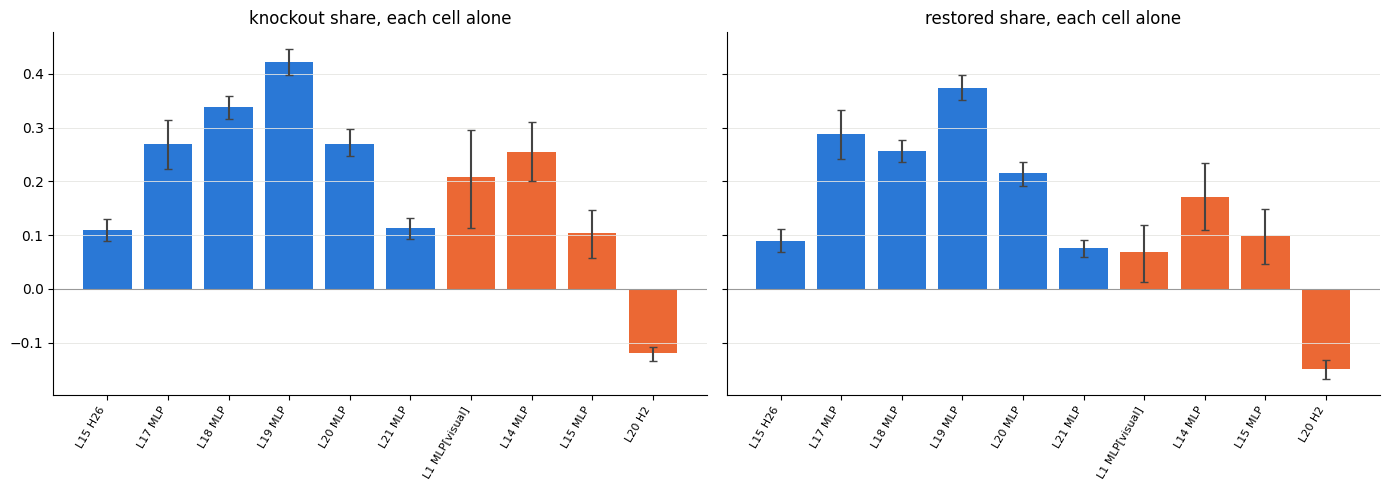

    [upload ok] summary


In [8]:
entries = []
for path in sorted(glob.glob(os.path.join(OUT_DIR, "C_batch_*.pt")), key=batch_number):
    entries.extend(torch.load(path))
good = [e for e in entries if e["ok"]]
assert len({e["question_id"] for e in good}) == len(good), "duplicated entries"
print(f"{len(entries)} entries, {len(good)} ok, {len(stage_ids) - len(good)} stage questions not done")
finite = [bool(np.isfinite(e["curve"].numpy()).all()) for e in good]
print(f"{len(good) - sum(finite)} questions with a non-finite value are excluded")
good = [e for e, ok_ in zip(good, finite) if ok_]

CV = np.stack([e["curve"].numpy() for e in good]).astype(np.float64)
dc = np.array([e["delta_clean"] for e in good])
dk = np.array([e["delta_corrupt"] for e in good])
sign = np.array([e["sign"] for e in good])
role = np.array([e["stratum"] for e in good])
split = np.array([e["split"] for e in good])
uid = np.array([e["uid"] for e in good])
fy = np.flatnonzero(role == "false_yes")
ct = np.flatnonzero(role == "true_yes")
S = len(STEP_NAMES)
si = {n: i for i, n in enumerate(STEP_NAMES)}
rng = np.random.default_rng(1)
N_BOOT = 1000


def share_sums(ix):
    den = (dk[ix] - dc[ix]).sum()
    knock = (CV[ix, :, 0] - dc[ix, None]).sum(0) / den
    restored = (CV[ix, :, 1] - dk[ix, None]).sum(0) / -den
    return np.stack([knock, restored], 1)


point = share_sums(fy)
draws = rng.integers(0, len(fy), size=(N_BOOT, len(fy)))
boots = np.stack([share_sums(fy[d]) for d in draws])
lo, hi = np.percentile(boots, 2.5, axis=0), np.percentile(boots, 97.5, axis=0)


def fmt(i, j):
    return f"{point[i, j]:+.2f} [{lo[i, j]:+.2f}, {hi[i, j]:+.2f}]"


pairs = sorted(set(uid[fy]) & set(uid[ct]))
fy_ix = {u: i for u, i in zip(uid[fy], fy)}
ct_ix = {u: i for u, i in zip(uid[ct], ct)}
a_ix = np.array([fy_ix[u] for u in pairs])
b_ix = np.array([ct_ix[u] for u in pairs])
pdraws = rng.integers(0, len(pairs), size=(N_BOOT, len(pairs)))
sup = [-sign[:, None] * (CV[:, :, 0] - dc[:, None]), sign[:, None] * (CV[:, :, 1] - dk[:, None])]
spec_pt, spec_lo, spec_hi = [], [], []
for arr in sup:
    diff = arr[a_ix] - arr[b_ix]
    means = diff[pdraws].mean(1)
    spec_pt.append(diff.mean(0))
    spec_lo.append(np.percentile(means, 2.5, axis=0))
    spec_hi.append(np.percentile(means, 97.5, axis=0))


def sfmt(i, j):
    return f"{spec_pt[j][i]:+.3f} [{spec_lo[j][i]:+.3f}, {spec_hi[j][i]:+.3f}]"


print(f"--- sets: shares over {len(fy)} driven false_yes questions and specificity over {len(pairs)} units ---")
sets = pd.DataFrame({"cells": [len(S_KEYS), len(K_KEYS), len(SK_KEYS)]}, index=["S", "K", "SK"])
sets["knockout"] = [fmt(si[n], 0) for n in sets.index]
sets["restored"] = [fmt(si[n], 1) for n in sets.index]
sets["spec knockout"] = [sfmt(si[n], 0) for n in sets.index]
sets["spec restored"] = [sfmt(si[n], 1) for n in sets.index]
print(sets.to_string())

print("--- each cell alone ---")
single = []
for k_ in SK_KEYS:
    i = si[f"single:{NAME[k_]}"]
    single.append({"cell": NAME[k_], "role": ROLE[k_], "knockout": fmt(i, 0), "restored": fmt(i, 1), "spec knockout": sfmt(i, 0), "spec restored": sfmt(i, 1)})
print(pd.DataFrame(single).to_string(index=False))


def loo_table(prefix, base, keys):
    rows = []
    for k_ in keys:
        i, b = si[f"{prefix}:{NAME[k_]}"], si[base]
        row = {"cell": NAME[k_], "role": ROLE[k_]}
        for j, nm in enumerate(["knockout", "restored"]):
            drop = point[b, j] - point[i, j]
            bd = boots[:, b, j] - boots[:, i, j]
            row[f"{nm} drop"] = f"{drop:+.2f} [{np.percentile(bd, 2.5):+.2f}, {np.percentile(bd, 97.5):+.2f}]"
        rows.append(row)
    return pd.DataFrame(rows)


print("--- leave one out of SK: share of both sets together minus share without the cell; positive means the cell carries that part of the effect ---")
print(loo_table("loo_SK", "SK", SK_KEYS).to_string(index=False))

BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#999999"
colors = {"shared": BLUE, "specific": ORANGE}
order = SK_KEYS
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
xs = np.arange(len(order))
for ax, j, title in [(axes[0], 0, "knockout share, each cell alone"), (axes[1], 1, "restored share, each cell alone")]:
    idx = [si[f"single:{NAME[k_]}"] for k_ in order]
    ax.bar(xs, point[idx, j], color=[colors[ROLE[k_]] for k_ in order])
    ax.errorbar(xs, point[idx, j], yerr=[point[idx, j] - lo[idx, j], hi[idx, j] - point[idx, j]], fmt="none", ecolor="#444444", capsize=3)
    ax.axhline(0, color=GREY, lw=0.8)
    ax.set_xticks(xs)
    ax.set_xticklabels([NAME[k_] for k_ in order], rotation=60, ha="right", fontsize=8)
    ax.set_title(title)
    ax.grid(color="#e5e5e2", lw=0.6, axis="y")
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "circuit_dissect.png"), dpi=150)
plt.show()

with open(os.path.join(OUT_DIR, "circuit_summary.json"), "w") as f:
    json.dump({
        "n_ok": len(good), "n_false_yes": int(len(fy)), "n_pairs": len(pairs), "step_names": STEP_NAMES, "config_order": CONFIG_NAMES,
        "shares": point.tolist(), "ci_lo": lo.tolist(), "ci_hi": hi.tolist(),
        "spec_knockout": spec_pt[0].tolist(), "spec_restored": spec_pt[1].tolist(),
        "s_cells": [NAME[k_] for k_ in S_KEYS], "k_cells": [NAME[k_] for k_ in K_KEYS],
    }, f)
if not upload("summary"):
    print(f"final upload failed; the batch files and summary are still in {OUT_DIR}, which is saved as this notebook's output")